# Balancing work, study and gym - an MDP

*Decision Theory, Fontys ICT 2026 Autumn Semester - László Balázs Kornis - design version 2, 9 Nov 2026*

This notebook has the design of my MDP, the environment code, the Sprint 1 test and the baselines, all in one place. Run it top to bottom (**Kernel -> Restart & Run All**).

## The story

I am a student and a freelance full-stack developer. Every working day I decide how to spend it: on client work for money now, on study for a better exam at the end of the period, or on the gym and rest for energy and sleep. New client tasks keep arriving, bugs make tasks take longer than planned, and some nights I sleep badly. There is a client deadline every week. The period ends with both a deadline and an exam on the last day.

**The trade-offs:**
- money now vs. a good exam grade at the end
- a hard day now vs. the risk of an exhausted day tomorrow (if I also sleep badly)
- gym costs time and money but makes bad sleep much less likely

## Time and episodes

- One time step is **one working day**.
- One episode is **20 working days** (four 5-day weeks). Day 20 is terminal.
- Discount factor **$\gamma = 0.95$**. The episode always ends, so $\gamma = 1$ would also be valid. I use 0.95 because money and progress now are worth a little more than later.
- Start state: energy 2, backlog 1, progress 0, day 1.

## State

s = (E, B, P, d), all discrete:

| Variable | Meaning | Values |
|---|---|---|
| E | energy in the morning | 0 = exhausted, 1 = low, 2 = normal |
| B | client backlog (open tasks) | 0–3 |
| P | study progress | 0–10 |
| d | working day | 1–20 |

**|S| = 3 · 4 · 11 · 20 = 2,640 states.** The state is a tuple (hashable), so it can be a key in a Q-table.

**Why it is Markov:** the day d is in the state because the weekly deadlines, the exam and the end of the episode depend on it. Tomorrow's energy depends only on today's action and tonight's sleep, which is a fresh random draw each night. Nothing else from the past matters.

## Actions

| Action | Kind of day | Allowed when |
|---|---|---|
| `work+work` | hard | E ≥ 1 |
| `study+study` | hard | E ≥ 1 |
| `study+gym` | hard, gym | E ≥ 1 |
| `rest+rest` | light | always (the only action at E = 0) |
| `rest+gym` | light, gym | E ≥ 1 |

## Transitions

Three random events per day, each with two outcomes.

**1. Slots.** Every work or study slot uses the **morning energy** and succeeds independently:

| Energy | Success per slot |
|---|---|
| E = 2 | **0.7** |
| E = 1 | **0.4** |
| E = 0 | only `rest+rest` is allowed |

- A successful **work** slot finishes one task: B −1, **+3**. If B = 0 there is nothing to finish.
- A successful **study** slot raises progress: P +1, **+1** (only while P < 10).
- A **gym** slot always happens: **−1** money, **+1** fitness.

**2. Deadline check** on days 5, 10, 15 and 20: if B > 0, bad review, **−4**.

**3. New task.** At the end of the day the client sends a new task with probability **0.4** (B +1, max 3). Scope changes count as new tasks.

**4. Night.** Bad sleep has probability **0.1** after a gym day, **0.6** otherwise.

| Sleep | Energy next morning |
|---|---|
| good | E′ = 2 |
| bad, after a light day | E′ = 1 |
| bad, after a hard day | E′ = 0 |

**5. Day 20 (terminal).** After the deadline check comes the exam:
- P ≥ 8: good grade, **+30**
- 5 ≤ P < 8: pass, **+15**
- P < 5: fail, **−10**

## Reward components

Every reward is the sum of named parts, which the code returns in `info["parts"]`.

| Component | Value |
|---|---|
| money | +3 per finished task, −1 per gym session |
| review | −4 per missed deadline |
| study | +1 per progress step, only while P < 10, so it cannot be farmed |
| fitness | +1 per gym session |
| exam | +30 / +15 / −10 on day 20 |

A rough scale check: about 0.4 · 20 = 8 new tasks arrive per period, so at most about 25–30 money. The exam swings between −10 and +30. Both goals have a similar size, so neither one trivially dominates.

## The environment

The code follows the optional coding standard:
- `env.actions`, `env.reset()` -> state, `env.step(a)` -> `(next_state, reward, done, info)`
- a hashable tuple state and its own seeded random generator
- `transitions(state, action)`, which lists every outcome with its probability

`step` draws one outcome from `transitions`, so the model used for planning (value iteration, Sprint 2) and the simulator can never disagree.

In [1]:
import random
import itertools
import math
import numpy as np
import matplotlib.pyplot as plt

# ---- named constants ----
N_DAYS          = 20
DEADLINE_DAYS   = {5, 10, 15, 20}
GAMMA           = 0.95
P_SUCCESS       = {2: 0.7, 1: 0.4}     # per slot, by morning energy
P_NEW_TASK      = 0.4
P_BAD_SLEEP_GYM = 0.1
P_BAD_SLEEP     = 0.6
MAX_BACKLOG     = 3
MAX_PROGRESS    = 10
TASK_REWARD     = 3
STUDY_REWARD    = 1
GYM_COST        = -1
FITNESS_REWARD  = 1
REVIEW_PENALTY  = -4
EXAM_GOOD, EXAM_PASS, EXAM_FAIL = 30, 15, -10
GOOD_GRADE, PASS_GRADE = 8, 5

ACTIONS   = ["work+work", "study+study", "study+gym", "rest+rest", "rest+gym"]
HARD_DAYS = {"work+work", "study+study", "study+gym"}
GYM_DAYS  = {"study+gym", "rest+gym"}

In [2]:
def _slot_successes(n_slots, p):
    # probability of k successes out of n independent slots (n = 0, 1 or 2)
    return [(k, math.comb(n_slots, k) * p**k * (1 - p)**(n_slots - k)) for k in range(n_slots + 1)]


class WorkStudyGymMDP:
    # one working day per step; state = (energy, backlog, progress, day)

    def __init__(self, seed=None):
        self.actions = ACTIONS
        self.rng = random.Random(seed)
        self.state = None

    # ---- standard interface ----
    def reset(self):
        self.state = (2, 1, 0, 1)
        return self.state

    def allowed_actions(self, state):
        energy = state[0]
        return ["rest+rest"] if energy == 0 else list(ACTIONS)

    def step(self, action):
        assert action in self.allowed_actions(self.state), f"action {action} not allowed in {self.state}"
        outcomes = self.transitions(self.state, action)
        x, acc = self.rng.random(), 0.0
        for p, s_next, reward, done, parts in outcomes:
            acc += p
            if x <= acc:
                break
        self.state = s_next
        return s_next, reward, done, {"parts": parts}

    # ---- the model: every outcome of (state, action) ----
    def transitions(self, state, action):
        # list of (probability, next_state, reward, done, parts); probabilities sum to 1
        E, B, P, d = state
        p = P_SUCCESS.get(E, 0.0)
        n_work  = 2 if action == "work+work" else 0
        n_study = {"study+study": 2, "study+gym": 1}.get(action, 0)
        gym = action in GYM_DAYS

        outcomes = []
        for k, pk in _slot_successes(max(n_work, n_study), p):
            # 1. slots
            parts = {"money": 0, "review": 0, "study": 0, "fitness": 0, "exam": 0}
            B1, P1 = B, P
            if n_work:
                done_tasks = min(B, k)
                B1 -= done_tasks
                parts["money"] += TASK_REWARD * done_tasks
            if n_study:
                steps = min(k, MAX_PROGRESS - P)
                P1 += steps
                parts["study"] += STUDY_REWARD * steps
            if gym:
                parts["money"] += GYM_COST
                parts["fitness"] += FITNESS_REWARD
            # 2. deadline check
            if d in DEADLINE_DAYS and B1 > 0:
                parts["review"] += REVIEW_PENALTY
            # 5. last day: exam, episode ends
            if d == N_DAYS:
                parts["exam"] = EXAM_GOOD if P1 >= GOOD_GRADE else EXAM_PASS if P1 >= PASS_GRADE else EXAM_FAIL
                outcomes.append((pk, (E, B1, P1, d + 1), sum(parts.values()), True, parts))
                continue
            # 3. new task, 4. night
            p_bad = P_BAD_SLEEP_GYM if gym else P_BAD_SLEEP
            for new_task, pt in [(1, P_NEW_TASK), (0, 1 - P_NEW_TASK)]:
                B2 = min(MAX_BACKLOG, B1 + new_task)
                for bad_sleep, ps in [(False, 1 - p_bad), (True, p_bad)]:
                    E2 = 2 if not bad_sleep else (0 if action in HARD_DAYS else 1)
                    outcomes.append((pk * pt * ps, (E2, B2, P1, d + 1), sum(parts.values()), False, dict(parts)))
        return outcomes


env = WorkStudyGymMDP(seed=0)
STATES = list(itertools.product(range(3), range(MAX_BACKLOG + 1), range(MAX_PROGRESS + 1), range(1, N_DAYS + 1)))
print("number of states:", len(STATES))

number of states: 2640


### Sanity checks

- For every state and allowed action, the outcome probabilities must sum to 1.
- One random episode must end after exactly 20 steps.

In [3]:
worst = max(abs(sum(o[0] for o in env.transitions(s, a)) - 1)
            for s in STATES for a in env.allowed_actions(s))
print("largest deviation from 1:", worst)
assert worst < 1e-12

s, done, steps, total = env.reset(), False, 0, 0.0
while not done:
    s, r, done, info = env.step(random.choice(env.allowed_actions(s)))
    steps += 1
    total += r
print("steps in one episode:", steps, "| undiscounted return:", total, "| last parts:", info["parts"])
assert steps == N_DAYS

largest deviation from 1: 0.0
steps in one episode: 20 | undiscounted return: 26.0 | last parts: {'money': -1, 'review': -4, 'study': 0, 'fitness': 1, 'exam': 30}


## Sprint 1 test: a tiny MDP whose behaviour I can argue for

Before trusting my code on the full model, I test it on a 2-state, 2-action slice where I can predict the outcome. $\gamma = 0.95$, no terminal state.

- **States:** energy `high` / `low`
- **Actions:** `work` / `rest`
- `high`, `work`: +3 with probability 0.7 (else 0) -> `low`
- `low`, `work`: +3 with probability p_low (else 0) -> stays `low`
- `rest` (either state): reward 0 -> `high`

**What I expect, argued in words.** Working in `high` earns 0.7 · 3 = 2.1 on average and makes me tired. In `low`, working still earns 0.4 · 3 = 1.2 per day on average. Resting earns nothing that day, only to get back to 2.1 the day after. So a rest day gives up 1.2 today to gain 2.1 − 1.2 = 0.9 tomorrow, and that gain is also discounted. With p_low = 0.4 I therefore expect **always work** to beat **work at high, rest at low**. If working tired pays much less (p_low = 0.2, so 0.6 per day), giving up a day costs little and resting should win.

**How I test it.** I simulate both policies, starting in `high`, for many episodes of 300 days each, and average the discounted return. Since 0.95^300 is tiny, 300 days is as good as forever here.


In [4]:
class TinyMDP:
    # 2 states, 2 actions, written in the same style as the full environment
    def __init__(self, p_low, seed=None):
        self.actions = ["work", "rest"]
        self.p_low = p_low
        self.rng = random.Random(seed)
        self.state = None

    def reset(self):
        self.state = "high"
        return self.state

    def step(self, action):
        assert action in self.actions
        if action == "rest":
            reward, s_next = 0, "high"
        else:
            p = 0.7 if self.state == "high" else self.p_low
            reward = 3 if self.rng.random() < p else 0
            s_next = "low"
        self.state = s_next
        return s_next, reward, False, {}


def simulate(policy, p_low, n_episodes=2000, n_days=300, seed=7):
    env = TinyMDP(p_low, seed=seed)
    returns = []
    for _ in range(n_episodes):
        s, G, disc = env.reset(), 0.0, 1.0
        for _ in range(n_days):
            s, r, done, info = env.step(policy[s])
            G += disc * r
            disc *= GAMMA
        returns.append(G)
    return np.mean(returns), np.std(returns, ddof=1)


rest_when_low = {"high": "work", "low": "rest"}
always_work   = {"high": "work", "low": "work"}
for p_low, expected_winner in [(0.4, "always work"), (0.2, "rest when low")]:
    m1, s1 = simulate(rest_when_low, p_low)
    m2, s2 = simulate(always_work, p_low)
    winner = "always work" if m2 > m1 else "rest when low"
    print(f"p_low = {p_low}:  rest when low: mean {m1:.2f} (SD {s1:.2f})  |  always work: mean {m2:.2f} (SD {s2:.2f})  ->  {winner} wins")
    assert winner == expected_winner, "the code does not behave as I argued"


p_low = 0.4:  rest when low: mean 21.70 (SD 3.17)  |  always work: mean 25.01 (SD 4.59)  ->  always work wins


p_low = 0.2:  rest when low: mean 21.70 (SD 3.17)  |  always work: mean 13.64 (SD 3.80)  ->  rest when low wins


## Baselines

Before any learning I evaluate two simple policies over 1,000 simulated periods:

- **Random policy:** uniform over the allowed actions every day. This is a sanity check of the environment and the floor any good policy must beat.
- **Hand-written rule:** rest at E = 0; work if B ≥ 2; otherwise study.

For each I report the mean and standard deviation (SD) of the discounted return, the exam outcomes, the number of missed deadlines and how often each action is used.


In [5]:
def random_policy(state, env, rng):
    return rng.choice(env.allowed_actions(state))

def rule_policy(state, env, rng):
    E, B, P, d = state
    if E == 0:
        return "rest+rest"
    return "work+work" if B >= 2 else "study+study"

def evaluate(policy, n_episodes=1000, seed=42):
    env, rng = WorkStudyGymMDP(seed=seed), random.Random(seed + 1)
    returns, exams, missed, counts = [], {30: 0, 15: 0, -10: 0}, [], {a: 0 for a in ACTIONS}
    for _ in range(n_episodes):
        s, done, G, disc, miss = env.reset(), False, 0.0, 1.0, 0
        while not done:
            a = policy(s, env, rng)
            counts[a] += 1
            s, r, done, info = env.step(a)
            G += disc * r
            disc *= GAMMA
            miss += info["parts"]["review"] < 0
        returns.append(G)
        exams[info["parts"]["exam"]] += 1
        missed.append(miss)
    returns = np.array(returns)
    return {"mean": returns.mean(), "sd": returns.std(ddof=1), "returns": returns,
            "exam good / pass / fail": (exams[30], exams[15], exams[-10]),
            "missed deadlines (avg)": np.mean(missed),
            "days per action (avg)": {a: round(c / n_episodes, 2) for a, c in counts.items()}}

results = {"random": evaluate(random_policy), "rule": evaluate(rule_policy)}
for name, res in results.items():
    print(f"--- {name} policy ---")
    print(f"discounted return: mean {res['mean']:.2f}, SD {res['sd']:.2f}")
    for k in ["exam good / pass / fail", "missed deadlines (avg)", "days per action (avg)"]:
        print(f"{k}: {res[k]}")

--- random policy ---
discounted return: mean 6.57, SD 7.03
exam good / pass / fail: (261, 441, 298)
missed deadlines (avg): 3.574
days per action (avg): {'work+work': 3.23, 'study+study': 3.17, 'study+gym': 3.13, 'rest+rest': 7.19, 'rest+gym': 3.28}
--- rule policy ---
discounted return: mean 19.14, SD 7.30
exam good / pass / fail: (604, 263, 133)
missed deadlines (avg): 3.185
days per action (avg): {'work+work': 6.01, 'study+study': 6.74, 'study+gym': 0.0, 'rest+rest': 7.25, 'rest+gym': 0.0}


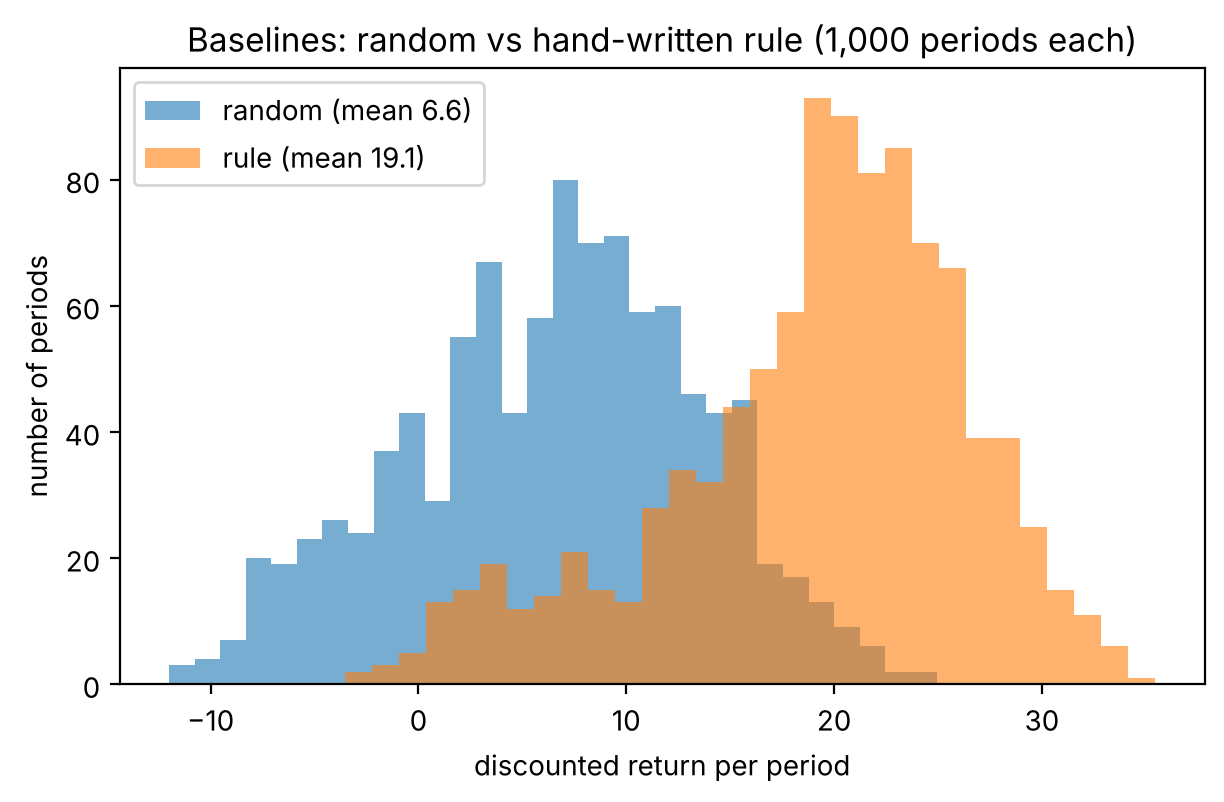

In [6]:
plt.figure(figsize=(7, 4))
for name, res in results.items():
    plt.hist(res["returns"], bins=30, alpha=0.6, label=f"{name} (mean {res['mean']:.1f})")
plt.xlabel("discounted return per period")
plt.ylabel("number of periods")
plt.title("Baselines: random vs hand-written rule (1,000 periods each)")
plt.legend()
plt.show()

### Gym check: does the sleep gap make gym worth it?

A simple check of my own, without any learning. I compare the hand-written rule with a variant that goes to the gym on every study day (`study+gym` instead of `study+study`), for the old sleep gap (0.2 / 0.4) and the new one (0.1 / 0.6). If gym only helps through sleep, the gym variant should gain more under the bigger gap.


In [7]:
def rule_with_gym(state, env, rng):
    E, B, P, d = state
    if E == 0:
        return "rest+rest"
    return "work+work" if B >= 2 else "study+gym"

def evaluate_with_sleep(policy, p_gym, p_no_gym):
    global P_BAD_SLEEP_GYM, P_BAD_SLEEP
    old = (P_BAD_SLEEP_GYM, P_BAD_SLEEP)
    P_BAD_SLEEP_GYM, P_BAD_SLEEP = p_gym, p_no_gym
    try:
        return evaluate(policy)
    finally:
        P_BAD_SLEEP_GYM, P_BAD_SLEEP = old

for gap in [(0.2, 0.4), (0.1, 0.6)]:
    plain = evaluate_with_sleep(rule_policy, *gap)
    gym   = evaluate_with_sleep(rule_with_gym, *gap)
    print(f"sleep gap {gap[0]} / {gap[1]}:  rule {plain['mean']:.2f}  |  rule with gym {gym['mean']:.2f}  |  difference {gym['mean'] - plain['mean']:+.2f}")


sleep gap 0.2 / 0.4:  rule 24.25  |  rule with gym 18.88  |  difference -5.36


sleep gap 0.1 / 0.6:  rule 19.14  |  rule with gym 17.29  |  difference -1.85


*My conclusion from the gym check:* ...

## How I think it behaves

*(my expectations, to be checked against value iteration in Sprint 2)*

- Work days before each Friday deadline when the backlog is high, study days when it is empty.
- Study concentrates when progress is still below 5 or 8 and few days are left. Above 8, studying is worth only +1 per step.
- After a hard day with bad sleep (E = 0) the agent is forced to rest. Whether it avoids hard days at E = 1 depends on the success probabilities (see the Sprint 1 test).
- Gym only pays off through better sleep since the −1 money and +1 fitness cancel out. With the large sleep gap (0.1 vs 0.6) I expect `study+gym` on days when tomorrow's energy matters, about once a week.

## Parameters and their expected impact

| Parameter | Value | Expected impact if it increases |
|---|---|---|
| $\gamma$ | 0.95 | more weight on the exam bonus and on delayed benefits |
| p_success (E = 2 / E = 1) | 0.7 / 0.4 | more output per day; a higher low-energy value makes resting less useful |
| p_new_task | 0.4 | more income available, more deadline pressure, less study time |
| review penalty | −4 | more work before deadlines |
| exam bonus | +30 / +15 / −10 | more study, especially near the thresholds 5 and 8 |
| p_bad_sleep (gym / no gym) | 0.1 / 0.6 | a bigger gap makes gym more valuable |
| fitness reward | +1 | a higher value makes gym worth doing for its own sake |

## Design changes

- **v1 -> v2 (9 Nov):** reduced the state from 31,680 to 2,640 states.
  - Removed the client leaves risk and the `find_client` action.
  - Removed the weekly gym counter and its consistency bonus.
  - Shortened the episode to 20 working days so it is more realistic.
  - Simplified the transitions to three random events per day:
    - Slots now use the morning energy, which removes the separate fatigue rule.
    - Scope changes and new tasks are merged into one event.
    - Sleep alone sets the next morning's energy.
  - Widened the sleep gap from 0.2 / 0.4 to 0.1 / 0.6, because with the smaller gap gym hardly seemed to matter. The gym check under Baselines tests this.
- **Notebook (9 Nov):** moved the design from a README into this notebook, together with the environment code, the Sprint 1 test and the baselines.

## Process: what works, what doesn't

**Where the idea comes from.** I looked at my own life for places where I keep making the same kind of decision. Balancing client work, study and the gym is something I face every day, so this MDP is an example from my everyday life.

**From too realistic to reasonable.** My first version was very broad and too realistic: 31,680 states, clients who could leave, an action to find new clients and a weekly gym counter. I simplified it to 2,640 states and three random events per day, so that it stays small and I can explain every part (see Design changes).

**Why a notebook.** I moved from a README with separate Python files to a Jupyter notebook. I can put code blocks and explanations next to each other, and the outputs are stored in the file, so everything is in one place and organised.

**What works so far:**
- For every state and action the outcome probabilities sum to 1, and every episode lasts exactly 20 days.
- The Sprint 1 test behaves the way I argued: always working wins when working tired still pays (p_low = 0.4), resting wins when it does not (p_low = 0.2).
- The baselines rank sensibly: the hand-written rule clearly beats the random policy.

**What doesn't work yet / open questions:** (from my baselines and the gym check)
- **Deadlines are too harsh.** Any open task counts at a deadline, even one that arrived the day before, so even my rule misses about 3 of the 4 deadlines. I considered giving every task its own due date, but that would multiply the number of states by 3 to 9, so I keep the simpler rule for now.
- **A full backlog silently drops new tasks.** When B = 3, a new task is lost without any penalty, so the agent never sees that cost.
- **Gym's same-day reward is zero** (−1 money, +1 fitness), so all of its value has to come through better sleep. My gym check shows that going to the gym on every study day still does not pay off for the simple rule.
- **Exhausted days (E = 0) are frequent.** My rule spends about 7 of 20 days on `rest+rest`, mostly because it is forced to at E = 0.
- **A work day with an empty backlog is allowed but does nothing.** It is rare, but it is a wasted action.

## Next sprints

- **Sprint 2 (Thu 10 Dec):** policy evaluation and value iteration on the full model with `env.transitions`; compare the result with the expert Q-table.
- **Sprint 3 (Thu 17 Dec):** Monte Carlo and $\varepsilon$-greedy from episodes; compare with the model-based answer; tests that show I can trust my results.
- **Sprint 4 (Thu 14 Jan):** Q-learning; comparison with the model and with Monte Carlo; presentation.